# Satellite risk and FMEA

## Goal

Connect the satellite disturbance model to fault sampling, histories, seed averaging and FMEA. The deterministic reference contributes **0.045 weighted missing packets** from the selected single-fault catalogue.

All schedules, distributions and rates are synthetic. This is a software demonstration, with no calibrated mission-reliability or classifier-accuracy claim.

```text
Copyright © 2024, United States Government, as represented by the Administrator
of the National Aeronautics and Space Administration. All rights reserved.

The "Fault Model Design tools - fmdtools version 2" software is licensed
under the Apache License, Version 2.0 (the "License"); you may not use this
file except in compliance with the License. You may obtain a copy of the
License at http://www.apache.org/licenses/LICENSE-2.0.

Unless required by applicable law or agreed to in writing, software distributed
under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR
CONDITIONS OF ANY KIND, either express or implied. See the License for the
specific language governing permissions and limitations under the License.
```

## Setup

Run from a checkout containing the satellite scaffold and disturbance variant, installed with `python -m pip install -e ".[examples]"` from the repository root. The model needs no downloads, model weights or additional dependencies.

This notebook calls `script_risk_analysis.py`; the complete definitions and weighting assumptions are in `risk_analysis.rst`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from fmdtools.analyze.result import Result
from fmdtools_examples.planetary_observation.script_risk_analysis import run_risk_analysis

reference = run_risk_analysis()
columns = ["sum_scenario_rate", "average_shortfall", "expected_shortfall"]
display(reference.fmea.as_table(sort_by="expected_shortfall")[columns])

,,sum_scenario_rate,average_shortfall,expected_shortfall
downlink,failed,0.01,2.00,0.0200
capture,failed,0.01,1.25,0.0125
process,failed,0.01,1.25,0.0125
capture,biased,0.02,0.00,0.0000


## Check the reference

The objective is two downlinked packets by minute six. Shortfall is `max(2 - downlinked, 0)`. Fault injection occurs at minute 1 or 3 with weights 0.25 and 0.75. Each capture/processing failure contributes `0.01 * (0.25*2 + 0.75*1) = 0.0125`. Downlink failure contributes 0.02; bias contributes zero to this delivery-count shortfall.

`average_shortfall` is conditional severity. `expected_shortfall` applies the synthetic fault rate once. Neither column should be labelled a total mission probability.

In [2]:
weighted_shortfall = sum(reference.fmea["expected_shortfall"].values())
weighted_failure = sum(reference.fmea["expected_delivery_failed"].values())
assert np.isclose(weighted_shortfall, 0.045)
assert np.isclose(weighted_failure, 0.03)
assert reference.mean_result["nominal.tend.classify.shortfall"] == 0
print(f"Fault-catalogue weighted shortfall: {weighted_shortfall:.4f} packets")
print(f"Fault-weighted delivery-failure indicator: {weighted_failure:.4f}")

Fault-catalogue weighted shortfall: 0.0450 packets
Fault-weighted delivery-failure indicator: 0.0300


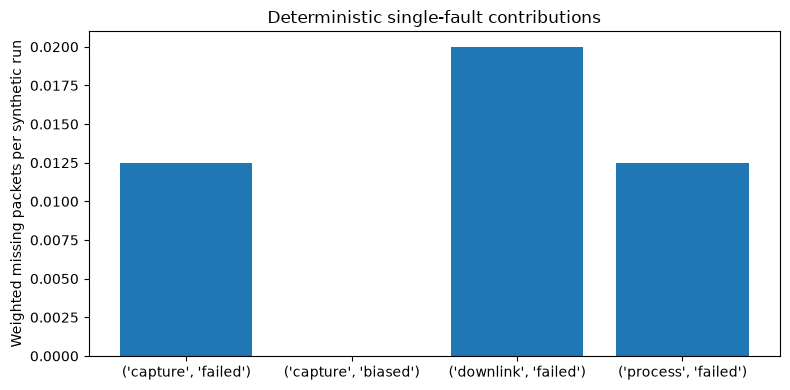

In [3]:
fig, ax = reference.fmea.as_plot(
    "expected_shortfall", title="Deterministic single-fault contributions",
    xlab="Fault mode", xlab_ang=0, figsize=(8, 4),
)
ax.set_ylabel("Weighted missing packets per synthetic run")
fig.tight_layout()
plt.show()

## Average seeded disturbances

Each of 32 distinct seeds has equal weight 1/32. No-fault and injected-fault simulations share the same seed. Their Gaussian/Bernoulli samples already follow the input distributions; latent input densities are not extra weights.

No-fault background losses remain separate. A negative paired change means a fault improved this count metric in that realization. Bias can select extra packets without improving scientific quality, which this model cannot measure.

In [4]:
seeds = tuple(range(32))
analysis = run_risk_analysis(seeds, stochastic=True)
display(analysis.fmea.as_table(sort_by="expected_shortfall")[
    ["average_shortfall", "expected_shortfall", "expected_delta_shortfall"]
])
print("No-fault mean shortfall:", analysis.mean_result["nominal.tend.classify.shortfall"])
print("No-fault delivery-failure fraction:", analysis.mean_result["nominal.tend.classify.delivery_failed"])
assert np.isclose(sum(analysis.fmea["sum_scenario_rate"].values()), 0.05)

,,average_shortfall,expected_shortfall,expected_delta_shortfall
downlink,failed,2.000000,0.020000,0.015312
capture,failed,1.296875,0.012969,0.008281
process,failed,1.296875,0.012969,0.008281
capture,biased,0.335938,0.006719,-0.002656


No-fault mean shortfall: 0.46875
No-fault delivery-failure fraction: 0.4375


## Inspect sampling variation

Calculate one full fault-catalogue contribution per seed. The histogram is variation between disturbance realizations, not a confidence interval. The standard error below is estimated across these complete seed-level totals because the fault scenarios within a seed are paired. It does not include uncertainty in fault rates or model assumptions. Thirty-two seeds are a runnable illustration, not a convergence result.

Mean catalogue contribution: 0.052656 packets
Estimated Monte Carlo standard error: 0.002200 packets


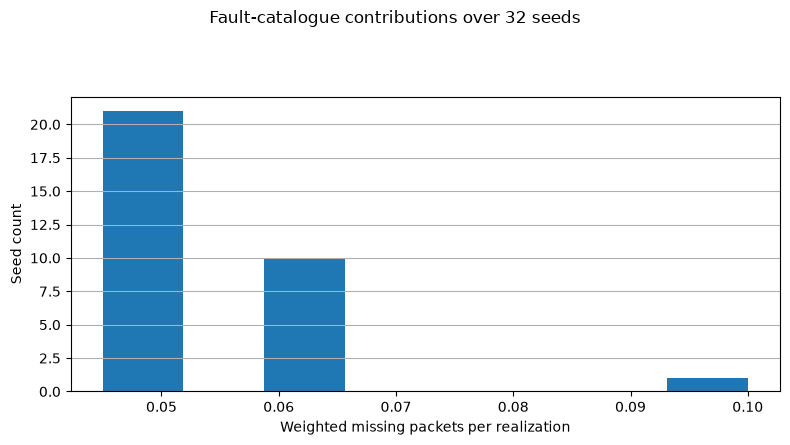

In [5]:
names = analysis.sample.scen_names()
rates = analysis.sample.get_scen_values("rate")
seed_risk = Result({
    f"seed_{seed}.catalogue_shortfall": analysis.results.get(f"seed_{seed}").get_scens(*names).get_metric(
        "shortfall", method="expected", rates=rates,
        prefix="tend.classify.", round_value=False,
    )
    for seed in seeds
})
values = np.asarray(list(seed_risk.values()))
assert np.isclose(values.mean(), sum(analysis.fmea["expected_shortfall"].values()))
standard_error = values.std(ddof=1) / np.sqrt(len(values))
print(f"Mean catalogue contribution: {values.mean():.6f} packets")
print(f"Estimated Monte Carlo standard error: {standard_error:.6f} packets")
fig, axes = seed_risk.plot_metric_dist(
    "catalogue_shortfall", comp_groups={"seeds": "default"}, cols=1, bins=8,
    title="Fault-catalogue contributions over 32 seeds",
    xlabels={"catalogue_shortfall": "Weighted missing packets per realization"},
    ylabel="Seed count", figsize=(8, 4), legend_loc=False,
)
fig.tight_layout()
plt.show()

## Trace and export the calculation

The original scenario definitions, per-seed terminal results and full histories are retained. The table below connects a scenario to its time, weight and terminal delivered-packet count. The CSV check uses memory and writes no files. The documentation gives explicit local-export commands for FMEA, results and histories.

In [6]:
import io
import pandas as pd

scenario = analysis.sample.scenarios()[0]
trace = analysis.histories.get("seed_0").get(scenario.name)
terminal = analysis.results.get("seed_0").get(scenario.name)
print("Scenario:", scenario.name, "time:", scenario.time, "rate:", scenario.rate)
assert terminal["tend.classify.shortfall"] == max(2 - trace["fxns.downlink.s.downlinked"][-1], 0)
display(pd.DataFrame({
    "minute": trace["time"],
    "selected": trace["fxns.process.s.selected"],
    "queued": trace["flows.buffer.s.queued"],
    "downlinked": trace["fxns.downlink.s.downlinked"],
}))
table = analysis.fmea.as_table(sort_by="expected_shortfall")
exported = pd.read_csv(io.StringIO(table.to_csv()), index_col=[0, 1])
np.testing.assert_allclose(exported["expected_shortfall"], table["expected_shortfall"])

Scenario: capture_failed_t1 time: 1 rate: 0.0025


,minute,selected,queued,downlinked
0,0.0,0,0,0
1,1.0,0,0,0
2,2.0,0,0,0
3,3.0,0,0,0
4,4.0,0,0,0
5,5.0,0,0,0
6,6.0,0,0,0


## Interpretation and next steps

The single-fault catalogue excludes joint faults and no-fault background losses. Do not add the background mean to these contributions or invent a complementary nominal probability. A complete mission-risk estimate would require an explicit exhaustive scenario model and supported occurrence assumptions.

The reference tests protect the weighting, scenario alignment and output paths. Next increments can connect the selection decision to an external model and define outcomes beyond packet counts, once suitable labels and assumptions exist.